# Whisper WER by accent group

Transcription performance per accent group. 

| Section | What it does | In the report |
|---|---|---|
| 1 | File paths and settings | – |
| 2 | Load data and choose the recordings | Methods |
| 3 | WER by accent group, and Hindi / African vs American (Cliff's δ, Mann–Whitney, BH), Kruskal–Wallis | Results (Fig. 1 + table) |
| 4 | Error types (substitutions, deletions, insertions) per group | Discussion (optional) |
| 5a | WER between the African L1 groups within SAA (Kruskal–Wallis, table and figure) | Methods / results (supports pooling) |
| 5b | WER between the AfriSpeech accents | Discussion (optional) |
| 6 | The same accents in SAA and AfriSpeech | Discussion (why the cross-corpus comparison is limited) |

**Which recordings are used?** For the WER results to match the acoustic analysis, this notebook can use exactly the same recordings: point `ANALYSIS_SAMPLE` at `analysis_master_table.csv`, which the analysis notebook writes to its output folder. If `ANALYSIS_SAMPLE = None`, every successfully scored recording in the manifest is used (minus the manual exclusions), so the counts will be higher than in the acoustic analysis.

The transcriptions file is not needed: `scored.csv` already contains the normalised reference and hypothesis, the error counts and the model name.

In [15]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown
from pathlib import Path

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)

## 1. File paths and settings

In [16]:
RESULTS_ROOT = Path('../results/')

PATHS = {
    'manifest': RESULTS_ROOT / 'dsp/runs/analysis_full/pitch/manifest_snapshot.csv',
    'scored':   RESULTS_ROOT / 'asr/runs/analysis_base_long/scored.csv',
}

# Use exactly the recordings from the acoustic analysis (recommended), or None to use all scored recordings
ANALYSIS_SAMPLE = 'analysis_outputs/analysis_master_table.csv'

OUTPUT_DIR = 'wer_outputs'

# Recordings excluded by decision (only needed when ANALYSIS_SAMPLE is None; the analysis sample already excludes them)
EXCLUDE_IDS = [
    'afrispeech_c74590e7e899b82d38a0599414907577',
    'afrispeech_ad2ddb8a0a31e06e12f2065866c4588e',
    'afrispeech_03bcfda67aaa67be96d4e44acadf3615',
    'afrispeech_12db0516db3e30de0d08e6eb0cb42370',
]

# Accent groups
AMERICAN_LABEL = 'american_english'
HINDI_LABEL = 'hindi'
AFRICAN_L1S = ['amharic', 'hausa', 'kiswahili', 'tigrigna', 'yoruba']
AFRISPEECH_DATASET = 'afrispeech'
SAA_DATASET = 'saa'
SAME_ACCENTS = ['hausa', 'kiswahili', 'yoruba']    # accents present in both corpora

Q_THRESHOLD = 0.05
COLORS = {'American': '#2a78d6', 'Hindi': '#1b9e70', 'African': '#e0632f', 'AfriSpeech': '#7b5ea7'}

FIG_DIR = os.path.join(OUTPUT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
def save(df, name, index=False): df.to_csv(os.path.join(OUTPUT_DIR, name), index=index)
def savefig(fig, name): fig.savefig(os.path.join(FIG_DIR, name), dpi=300, bbox_inches='tight')

TABLE_CSS = [dict(selector='caption', props=[('caption-side', 'top'), ('text-align', 'left'), ('padding-bottom', '6px')])]
def show(df, title, note=None, formats=None, index=False):
    sty = df.style.set_caption(f'<b>{title}</b>').set_table_styles(TABLE_CSS).format(formats or {}, na_rep='–')
    if not index: sty = sty.hide(axis='index')
    display(sty)
    if note: display(Markdown(f'<span style="font-size:0.9em">{note}</span>'))
def pfmt(p): return '<0.001' if p < 0.001 else f'{p:.3f}'
def cliff(a, b):
    # Cliff's delta (P(a > b) - P(a < b)) and the two-sided Mann–Whitney p-value
    u = stats.mannwhitneyu(a, b, alternative='two-sided')
    return 2 * u.statistic / (len(a) * len(b)) - 1, u.pvalue
def magnitude(x):
    a = abs(x)
    return 'large' if a >= 0.474 else 'medium' if a >= 0.33 else 'small' if a >= 0.147 else 'negligible'
FIGS = {}

## 2. Load data and choose the recordings

WER per recording comes from `scored.csv`: WER = (S + D + I) / N after text normalisation. Only recordings whose transcription and scoring succeeded are used.

In [17]:
for k, p in PATHS.items():
    if not os.path.exists(p): raise FileNotFoundError(f'{k}: file not found at {p}. Update PATHS in Section 1.')
man = pd.read_csv(PATHS['manifest'])
sc = pd.read_csv(PATHS['scored'])
n_scored = len(sc)
for col in ('transcription_status', 'scoring_status', 'status'):
    if col in sc.columns: sc = sc[sc[col] == 'ok']

man_cols = [c for c in ['sample_id', 'dataset', 'accent_group', 'sex', 'domain'] if c in man.columns]
sc_cols = [c for c in ['sample_id', 'wer', 'substitutions', 'deletions', 'insertions', 'hits', 'n_reference_words', 'model_name', 'decode_mode'] if c in sc.columns]
d = man[man_cols].merge(sc[sc_cols], on='sample_id')
log = [('Scored recordings in scored.csv', n_scored), ('Scored successfully and in the manifest', len(d))]

if ANALYSIS_SAMPLE is not None:
    if not os.path.exists(ANALYSIS_SAMPLE):
        raise FileNotFoundError(f'ANALYSIS_SAMPLE not found at {ANALYSIS_SAMPLE}. Run the analysis notebook first, fix the path, or set it to None.')
    keep = set(pd.read_csv(ANALYSIS_SAMPLE, usecols=['sample_id']).sample_id)
    missing = keep - set(d.sample_id)
    if missing: print(f'Warning: {len(missing)} analysis recordings are not in this manifest/scored file, e.g. {sorted(missing)[:3]}')
    d = d[d.sample_id.isin(keep)]
    log.append(('Restricted to the acoustic-analysis recordings', len(d)))
else:
    d = d[~d.sample_id.isin(EXCLUDE_IDS)]
    log.append(('After manual exclusions', len(d)))

def assign_group(r):
    if r.dataset == AFRISPEECH_DATASET: return 'AfriSpeech'
    if r.dataset == SAA_DATASET and r.accent_group == AMERICAN_LABEL: return 'American'
    if r.dataset == SAA_DATASET and r.accent_group == HINDI_LABEL: return 'Hindi'
    if r.dataset == SAA_DATASET and r.accent_group in AFRICAN_L1S: return 'African'
    return 'Other'
d['group'] = d.apply(assign_group, axis=1)
if (d.group == 'Other').any():
    d = d[d.group != 'Other']
    log.append(('After dropping recordings outside the analysis groups', len(d)))
d = d.reset_index(drop=True)

GROUPS = ['American', 'Hindi', 'African', 'AfriSpeech']
SAA_GROUPS = ['American', 'Hindi', 'African']
show(pd.DataFrame(log, columns=['Step', 'Recordings']), 'Recordings used')
if 'model_name' in d.columns:
    print('ASR model(s):', d.model_name.unique().tolist(), '| decode mode(s):', d.decode_mode.unique().tolist() if 'decode_mode' in d.columns else '–')

Step,Recordings
Scored recordings in scored.csv,580
Scored successfully and in the manifest,546
Restricted to the acoustic-analysis recordings,535


ASR model(s): ['openai/whisper-base'] | decode mode(s): ['sequential_long_form']


## 3. WER by accent group

- **Pooled WER**: all errors in the group divided by all reference words (each word counts equally).
- **Mean WER**: average of the per-recording WERs (each speaker counts equally).
- **Zero WER**: percentage of recordings transcribed perfectly.

The three SAA groups read the same paragraph and are compared directly. **Kruskal–Wallis** tests whether WER differs across the three groups; **Hindi vs American** and **African vs American** are then compared with Mann–Whitney tests and Cliff's δ, with Benjamini–Hochberg correction over the two comparisons. AfriSpeech is shown for reference only (different text and recording conditions).

In [18]:
def wer_summary(t):
    return dict(n=len(t),
                pooled_WER=100 * (t.substitutions + t.deletions + t.insertions).sum() / t.n_reference_words.sum(),
                mean_WER=100 * t.wer.mean(), median_WER=100 * t.wer.median(),
                IQR=f'{100 * t.wer.quantile(0.25):.1f}–{100 * t.wer.quantile(0.75):.1f}',
                zero_WER_pct=100 * (t.wer == 0).mean())
by_group = pd.DataFrame([dict(Group=g, **wer_summary(d[d.group == g])) for g in GROUPS])
save(by_group, 'TABLE_wer_by_group.csv')

kw = stats.kruskal(*[d.wer[d.group == g] for g in SAA_GROUPS])
comp = []
for g in ['Hindi', 'African', 'AfriSpeech']:
    dl, p = cliff(d.wer[d.group == g], d.wer[d.group == 'American'])
    comp.append(dict(Comparison=f'{g} vs American', delta=dl, Size=magnitude(dl), p=p))
comp = pd.DataFrame(comp); comp['q'] = multipletests(comp.p, method='fdr_bh')[1]
save(comp, 'TABLE_wer_comparisons.csv')

# One table for the report: summary per group + comparison with American
table_wer = by_group.merge(comp.assign(Group=comp.Comparison.str.replace(' vs American', ''))[['Group', 'delta', 'p', 'q']], on='Group', how='left')
table_wer = table_wer.rename(columns={'pooled_WER': 'Pooled WER (%)', 'mean_WER': 'Mean WER (%)', 'median_WER': 'Median WER (%)',
                                      'IQR': 'IQR (%)', 'zero_WER_pct': 'Zero WER (%)', 'delta': 'δ vs American',
                                      'p': 'p vs American', 'q': 'q vs American'})
show(table_wer, 'TABLE. WER per accent group',
     note=f"δ = Cliff's delta vs American (positive = higher WER). p from Mann–Whitney; q = Benjamini–Hochberg over the three comparisons. "
          f"AfriSpeech vs American also differs in text and recording conditions, so its δ reflects corpus as well as accent. "
          f"Kruskal–Wallis across the three SAA groups: H = {kw.statistic:.1f}, p = {kw.pvalue:.1e}.",
     formats={'Pooled WER (%)': '{:.1f}', 'Mean WER (%)': '{:.1f}', 'Median WER (%)': '{:.1f}', 'Zero WER (%)': '{:.0f}',
              'δ vs American': '{:+.2f}', 'p vs American': pfmt, 'q vs American': pfmt})
print(f'Kruskal–Wallis (American, Hindi, African): H = {kw.statistic:.2f}, df = 2, p = {kw.pvalue:.2e}')

Group,n,Pooled WER (%),Mean WER (%),Median WER (%),IQR (%),Zero WER (%),δ vs American,p vs American,q vs American
American,306,1.8,1.8,1.4,0.0–2.9,47,–,–,–
Hindi,18,2.7,2.7,2.2,1.4–2.9,22,+0.26,0.047,0.047
African,46,12.0,12.0,9.4,5.8–15.6,4,+0.81,<0.001,<0.001
AfriSpeech,165,42.2,45.3,40.0,21.7–62.5,5,+0.92,<0.001,<0.001


<span style="font-size:0.9em">δ = Cliff's delta vs American (positive = higher WER). p from Mann–Whitney; q = Benjamini–Hochberg over the three comparisons. AfriSpeech vs American also differs in text and recording conditions, so its δ reflects corpus as well as accent. Kruskal–Wallis across the three SAA groups: H = 88.9, p = 4.9e-20.</span>

Kruskal–Wallis (American, Hindi, African): H = 88.94, df = 2, p = 4.85e-20


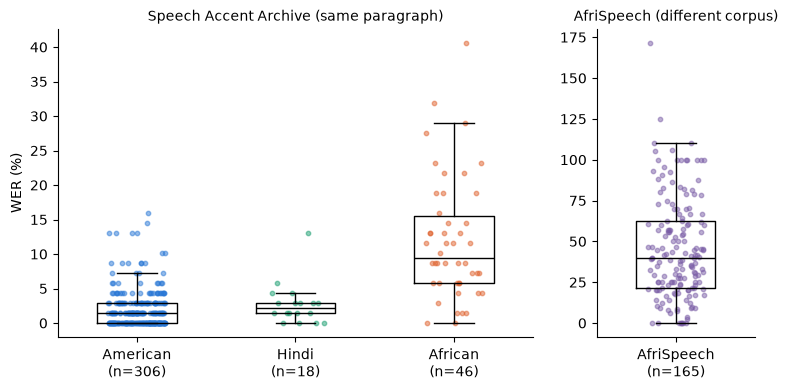

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), gridspec_kw={'width_ratios': [3, 1]})
rng_j = np.random.default_rng(0)
for ax, gs, title in [(axes[0], SAA_GROUPS, 'Speech Accent Archive (same paragraph)'),
                      (axes[1], ['AfriSpeech'], 'AfriSpeech (different corpus)')]:
    for i, g in enumerate(gs):
        y = 100 * d.wer[d.group == g].values
        ax.boxplot(y, positions=[i], widths=0.5, showfliers=False, medianprops=dict(color='black'))
        ax.scatter(i + rng_j.uniform(-0.18, 0.18, len(y)), y, s=10, alpha=0.5, color=COLORS[g])
    ax.set_xticks(range(len(gs)), [f'{g}\n(n={(d.group == g).sum()})' for g in gs])
    ax.set_title(title, fontsize=10); ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('WER (%)')
savefig(fig, 'fig1_wer_by_group.png'); FIGS['wer'] = fig; plt.show()

## 4. Error types per group

Share of all errors that are substitutions (wrong word), deletions (missed word) and insertions (extra word), and errors per 100 reference words. Useful for the discussion: it shows *how* Whisper fails for each group.

Group,Errors,Substitutions (%),Deletions (%),Insertions (%),Substitutions per 100 words,Deletions per 100 words,Insertions per 100 words
American,385,68.3,12.2,19.5,1.2,0.2,0.4
Hindi,34,73.5,8.8,17.6,2.0,0.2,0.5
African,381,67.5,12.3,20.2,8.1,1.5,2.4
AfriSpeech,1354,55.8,9.9,34.3,23.6,4.2,14.5


<span style="font-size:0.9em">Percentages are shares of all errors in the group; "per 100 words" adds up to the pooled WER.</span>

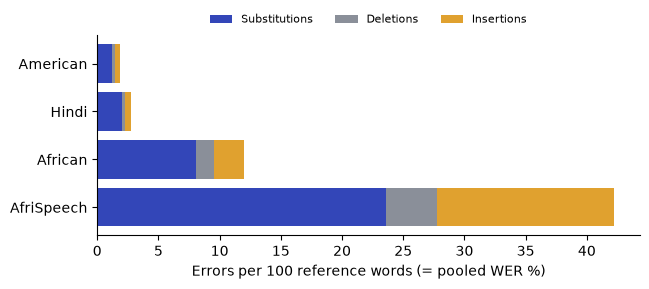

In [20]:
rows = []
for g in GROUPS:
    t = d[d.group == g]; S, D_, I = t.substitutions.sum(), t.deletions.sum(), t.insertions.sum(); E = S + D_ + I; N = t.n_reference_words.sum()
    rows.append({'Group': g, 'Errors': int(E), 'Substitutions (%)': 100 * S / E, 'Deletions (%)': 100 * D_ / E, 'Insertions (%)': 100 * I / E,
                 'Substitutions per 100 words': 100 * S / N, 'Deletions per 100 words': 100 * D_ / N, 'Insertions per 100 words': 100 * I / N})
err = pd.DataFrame(rows); save(err, 'TABLE_error_types.csv')
show(err, 'Error types per group', note='Percentages are shares of all errors in the group; "per 100 words" adds up to the pooled WER.',
     formats={c: '{:.1f}' for c in err.columns if c not in ('Group', 'Errors')})

fig, ax = plt.subplots(figsize=(7, 2.6))
parts = [('Substitutions per 100 words', '#3346b8'), ('Deletions per 100 words', '#8a8f99'), ('Insertions per 100 words', '#e0a12f')]
for i, g in enumerate(GROUPS):
    left = 0
    for col, colr in parts:
        v = err.loc[err.Group == g, col].iloc[0]
        ax.barh(i, v, left=left, color=colr, label=col.replace(' per 100 words', '') if i == 0 else None); left += v
ax.set_yticks(range(len(GROUPS)), GROUPS); ax.invert_yaxis(); ax.set_xlabel('Errors per 100 reference words (= pooled WER %)')
ax.legend(frameon=False, ncol=3, fontsize=8, loc='lower center', bbox_to_anchor=(0.5, 1.0)); ax.spines[['top', 'right']].set_visible(False)
savefig(fig, 'fig_error_types.png'); FIGS['errors'] = fig; plt.show()

## 5. Do WERs differ between the African accents?

### 5a. Between the African L1 groups within SAA

All SAA African speakers read the same paragraph, so any WER difference between Amharic, Hausa, Kiswahili, Tigrigna and Yoruba speakers would reflect the accent. Kruskal–Wallis test across the five L1 groups, with ε² = H / (n − 1) as the effect size. If there is no difference, African speakers can be analysed as one group (as in the acoustic analysis). With 5–18 speakers per L1, only large differences could be detected.

African L1,n,Pooled WER (%),Mean WER (%),Median WER (%),IQR (%),Zero WER (%)
amharic,18,14.1,14.1,11.6,6.2–21.7,11
hausa,9,8.9,8.9,8.7,4.3–13.0,0
kiswahili,7,11.4,11.4,7.2,5.8–13.8,0
tigrigna,7,10.4,10.4,10.1,8.0–12.3,0
yoruba,5,13.3,13.3,11.6,8.7–18.8,0


<span style="font-size:0.9em">Kruskal–Wallis across the 5 L1 groups: H(4) = 1.48, p = 0.830, ε² = 0.033.</span>

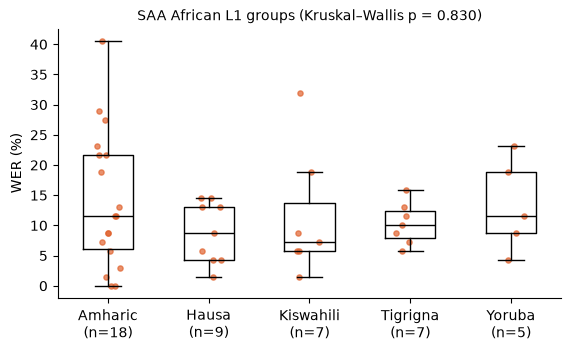

In [21]:
def by_accent(sub):
    return pd.DataFrame([dict(Accent=a, **wer_summary(t)) for a, t in sub.groupby('accent_group')])
fmt = {'pooled_WER': '{:.1f}', 'mean_WER': '{:.1f}', 'median_WER': '{:.1f}', 'zero_WER_pct': '{:.0f}'}

saa_af = d[d.group == 'African']
l1_table = by_accent(saa_af).sort_values('n', ascending=False)
kw_l1 = stats.kruskal(*[x.wer for _, x in saa_af.groupby('accent_group')])
eps2_l1 = kw_l1.statistic / (len(saa_af) - 1)
save(l1_table, 'TABLE_wer_SAA_African_L1s.csv')
show(l1_table.rename(columns={'Accent': 'African L1', 'pooled_WER': 'Pooled WER (%)', 'mean_WER': 'Mean WER (%)', 'median_WER': 'Median WER (%)',
                              'IQR': 'IQR (%)', 'zero_WER_pct': 'Zero WER (%)'}),
     'TABLE. WER by African L1 group (SAA)',
     note=f'Kruskal–Wallis across the {saa_af.accent_group.nunique()} L1 groups: H({saa_af.accent_group.nunique() - 1}) = {kw_l1.statistic:.2f}, '
          f'p = {pfmt(kw_l1.pvalue)}, ε² = {eps2_l1:.3f}.',
     formats={'Pooled WER (%)': '{:.1f}', 'Mean WER (%)': '{:.1f}', 'Median WER (%)': '{:.1f}', 'Zero WER (%)': '{:.0f}'})

fig, ax = plt.subplots(figsize=(6.5, 3.5))
order = l1_table.Accent.tolist()
for i, a in enumerate(order):
    y = 100 * saa_af.wer[saa_af.accent_group == a].values
    ax.boxplot(y, positions=[i], widths=0.5, showfliers=False, medianprops=dict(color='black'))
    ax.scatter(i + rng_j.uniform(-0.15, 0.15, len(y)), y, s=14, alpha=0.7, color=COLORS['African'])
ax.set_xticks(range(len(order)), [f'{a.capitalize()}\n(n={(saa_af.accent_group == a).sum()})' for a in order])
ax.set_ylabel('WER (%)'); ax.set_title(f'SAA African L1 groups (Kruskal–Wallis p = {pfmt(kw_l1.pvalue)})', fontsize=10)
ax.spines[['top', 'right']].set_visible(False)
savefig(fig, 'fig_wer_SAA_African_L1s.png'); FIGS['l1'] = fig; plt.show()

### 5b. Between the accents within AfriSpeech

The same test for the three AfriSpeech accents. Read any difference with care: the AfriSpeech accents did not differ acoustically, so a WER difference here more likely reflects what was read (clinical vs general text) and how it was recorded.

In [22]:
as_sub = d[d.group == 'AfriSpeech']
as_table = by_accent(as_sub)
kw_as = stats.kruskal(*[x.wer for _, x in as_sub.groupby('accent_group')])
save(as_table, 'TABLE_wer_AfriSpeech_accents.csv')
show(as_table, 'WER by accent: AfriSpeech', note=f'Kruskal–Wallis: H({as_sub.accent_group.nunique() - 1}) = {kw_as.statistic:.2f}, p = {pfmt(kw_as.pvalue)}.', formats=fmt)

if 'domain' in d.columns:
    dom = (as_sub.groupby(['accent_group', 'domain']).wer.agg(['size', 'mean']).assign(mean=lambda x: 100 * x['mean'])
             .rename(columns={'size': 'n', 'mean': 'Mean WER (%)'}).reset_index())
    save(dom, 'TABLE_afrispeech_wer_by_domain.csv')
    show(dom, 'AfriSpeech WER by accent and domain (clinical vs general text)', formats={'Mean WER (%)': '{:.1f}'})

Accent,n,pooled_WER,mean_WER,median_WER,IQR,zero_WER_pct
hausa,26,45.2,49.2,42.2,25.7–69.6,4
kiswahili,44,29.6,31.8,22.4,11.9–44.8,7
yoruba,95,47.7,50.5,45.0,27.9–66.7,4


<span style="font-size:0.9em">Kruskal–Wallis: H(2) = 14.34, p = <0.001.</span>

accent_group,domain,n,Mean WER (%)
hausa,clinical,17,57.6
hausa,general,9,33.4
kiswahili,clinical,17,27.5
kiswahili,general,27,34.6
yoruba,clinical,43,54.2
yoruba,general,52,47.4


## 6. The same accents in SAA and AfriSpeech

Hausa, Kiswahili and Yoruba speakers appear in both corpora. If WER depended only on accent, the same accent should get similar WER in both. Mann–Whitney tests with Cliff's δ, Benjamini–Hochberg corrected over the three accents.

Accent,n SAA,n AfriSpeech,Mean WER SAA (%),Mean WER AfriSpeech (%),Pooled WER SAA (%),Pooled WER AfriSpeech (%),Ratio (AfriSpeech / SAA),δ AfriSpeech vs SAA,p,q
hausa,9,26,8.9,49.2,8.9,45.2,5.6,+0.89,<0.001,<0.001
kiswahili,7,44,11.4,31.8,11.4,29.6,2.8,+0.55,0.021,0.021
yoruba,5,95,13.3,50.5,13.3,47.7,3.8,+0.81,0.002,0.004


<span style="font-size:0.9em">δ = Cliff's delta (positive = higher WER in AfriSpeech). p from Mann–Whitney; q = Benjamini–Hochberg over the three accents.</span>

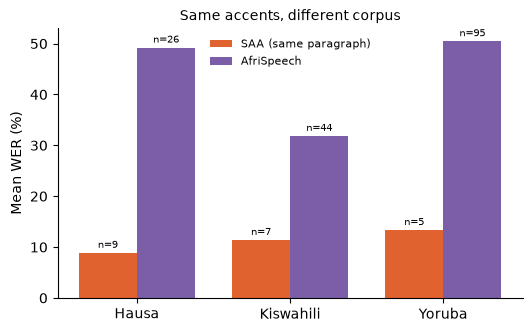

In [23]:
rows = []
for a in SAME_ACCENTS:
    s = d[(d.group == 'African') & (d.accent_group == a)]
    f = d[(d.group == 'AfriSpeech') & (d.accent_group == a)]
    if len(s) == 0 or len(f) == 0: continue
    dl, p = cliff(f.wer, s.wer)
    rows.append({'Accent': a, 'n SAA': len(s), 'n AfriSpeech': len(f),
                 'Mean WER SAA (%)': 100 * s.wer.mean(), 'Mean WER AfriSpeech (%)': 100 * f.wer.mean(),
                 'Pooled WER SAA (%)': wer_summary(s)['pooled_WER'], 'Pooled WER AfriSpeech (%)': wer_summary(f)['pooled_WER'],
                 'Ratio (AfriSpeech / SAA)': f.wer.mean() / s.wer.mean(), 'δ AfriSpeech vs SAA': dl, 'p': p})
same = pd.DataFrame(rows); same['q'] = multipletests(same.p, method='fdr_bh')[1]
save(same, 'TABLE_same_accents_by_corpus.csv')
show(same, 'TABLE. Same accents, different corpus: WER in SAA vs AfriSpeech',
     note="δ = Cliff's delta (positive = higher WER in AfriSpeech). p from Mann–Whitney; q = Benjamini–Hochberg over the three accents.",
     formats={c: '{:.1f}' for c in same.columns if '(%)' in c or 'Ratio' in c} | {'δ AfriSpeech vs SAA': '{:+.2f}', 'p': pfmt, 'q': pfmt})

fig, ax = plt.subplots(figsize=(6, 3.5))
x = np.arange(len(same)); w = 0.38
ax.bar(x - w / 2, same['Mean WER SAA (%)'], w, color=COLORS['African'], label='SAA (same paragraph)')
ax.bar(x + w / 2, same['Mean WER AfriSpeech (%)'], w, color=COLORS['AfriSpeech'], label='AfriSpeech')
for i, r in same.iterrows():
    ax.text(i - w / 2, r['Mean WER SAA (%)'] + 1, f"n={r['n SAA']}", ha='center', fontsize=7)
    ax.text(i + w / 2, r['Mean WER AfriSpeech (%)'] + 1, f"n={r['n AfriSpeech']}", ha='center', fontsize=7)
ax.set_xticks(x, same.Accent.str.capitalize()); ax.set_ylabel('Mean WER (%)')
ax.set_title('Same accents, different corpus', fontsize=10); ax.legend(frameon=False, fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
savefig(fig, 'fig_same_accents_by_corpus.png'); FIGS['same'] = fig; plt.show()